<a href="https://colab.research.google.com/github/D-LukeSherman/ECGR-4105/blob/main/Homework6/Homework6Problem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [451]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
np.random.seed(42)

In [452]:
# Use the URL for the raw CSV data
url = 'https://raw.githubusercontent.com/D-LukeSherman/ECGR-4105/refs/heads/main/Homework4/Housing.csv'

dataset = pd.read_csv(url)

# Preprocessing

varlist = ['mainroad', 'guestroom', 'basement', 'hotwaterheating',
            'airconditioning', 'prefarea']

def binary_map(x):
    return x.map({'yes': 1, 'no': 0})

dataset[varlist] = dataset[varlist].apply(binary_map)

# Map furnishingstatus: furnished -> 2, semi-furnished -> 1, unfurnished -> 0
status_map = {'furnished': 2, 'semi-furnished': 1, 'unfurnished': 0}
dataset['furnishingstatus'] = dataset['furnishingstatus'].map(status_map)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
num_vars = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
            'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

dataset[num_vars] = scaler.fit_transform(dataset[num_vars])


x = dataset.iloc[:, 1:13].values
y = dataset.iloc[:, 0].values

Xtrain, Xtest, ytrain, ytest = train_test_split(x, y, test_size = 0.2,
                                                random_state=42)

In [453]:
t_u_train = torch.tensor(Xtrain, dtype=torch.float32)
t_c_train = torch.tensor(ytrain, dtype=torch.float32).unsqueeze(1)

t_u_val = torch.tensor(Xtest, dtype=torch.float32)
t_c_val = torch.tensor(ytest, dtype=torch.float32).unsqueeze(1)

In [454]:
def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
    train_loss_history = []
    val_loss_history = []

    for epoch in range(1, n_epochs + 1):
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        t_p_val = model(t_u_val)
        loss_val = loss_fn(t_p_val, t_c_val)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        train_loss_history.append(loss_train.item())
        val_loss_history.append(loss_val.item())

    return train_loss_history, val_loss_history

In [455]:
epochs = 3000
nodes = 8
model = nn.Sequential(
    nn.Linear(12, nodes),
    nn.ReLU(),
    nn.Linear(nodes, nodes),
    nn.ReLU(),
    nn.Linear(nodes, nodes),
    nn.ReLU(),
    nn.Linear(nodes, 1)
  )
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

In [456]:
train_loss, val_loss = training_loop(
  n_epochs = epochs,
  optimizer = optimizer,
  model = model,
  loss_fn = nn.MSELoss(),
  t_u_train = t_u_train,
  t_u_val = t_u_val,
  t_c_train = t_c_train,
  t_c_val = t_c_val
)

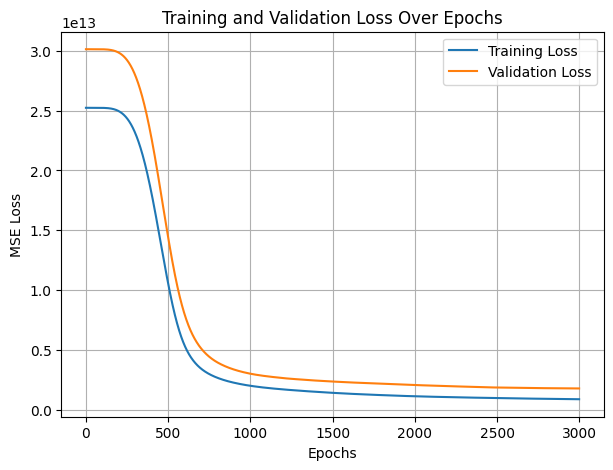

In [457]:
# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [458]:
print(val_loss[epochs - 1] / 10**12)
print(train_loss[epochs - 1] / 10**12)

1.78259034112
0.882029756416


In [459]:
print("RMSE Error:", (math.sqrt(val_loss[epochs - 1])))
r2error = 1 - (val_loss[epochs - 1] / t_c_val.var())
print("R2 Error:", r2error)
#

RMSE Error: 1335136.8248685226
R2 Error: tensor(0.6506)
